<a href="https://colab.research.google.com/github/PunamBhatia/LogicMojo-AI-ML-April26-Punam/blob/main/TransferLearning/CaliforniaHousingPrice_LR_RF_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn

#we dont need nn here as datasize is small and no of columns also less
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

SEED=42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)


cuda


In [2]:
from datasets import load_dataset
raw=load_dataset("gvlassis/california_housing")
print(raw)

README.md:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  846kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  105kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16640 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
        num_rows: 16640
    })
    validation: Dataset({
        features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal'],
        num_rows: 2000
    })
})


In [3]:
#Lets concatinate Train, Test and Split together in dataframe as we want to train Linear Regression first
#for MLP we will split it in Train,Test, Val again
#raw.keys() returns train, validation and test headers
df=pd.concat([raw[record].to_pandas() for record in raw.keys()],ignore_index=True)
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
#target_col=[c for c in df.columns if c.str.contains('value','target','medhouseval', case=False)]

target_col_possible_names=['value','target','medhouseval']
target_col=[c for c in df.columns if c.lower() in target_col_possible_names ]
target_col=target_col[0]
print(target_col)
#df.columns[-1] retrieves the name or label of the very last column in a Pandas DataFrame.

#fetch features columns except target
features_cols=[c for c in df.columns if c.lower()!=target_col.lower()]
print(features_cols)
df.describe()

MedHouseVal
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


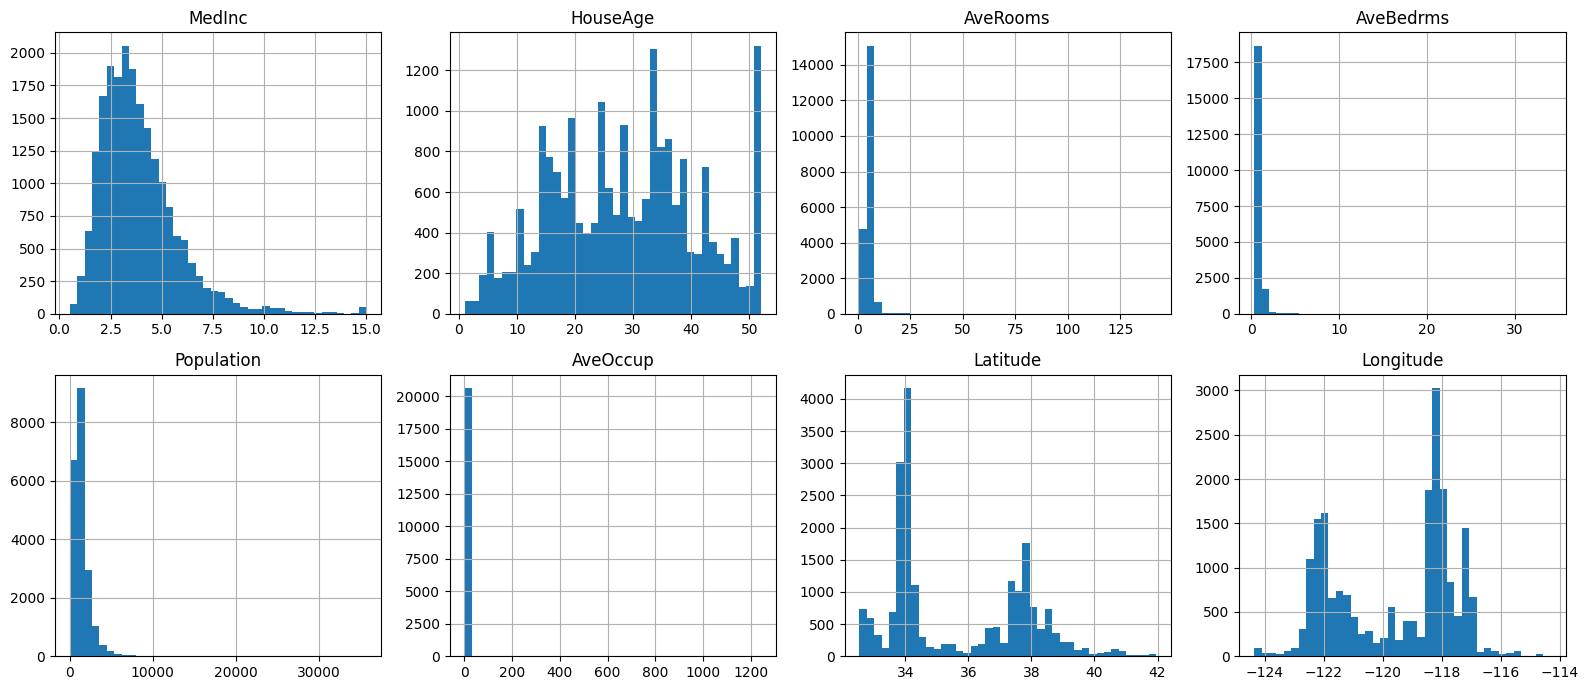

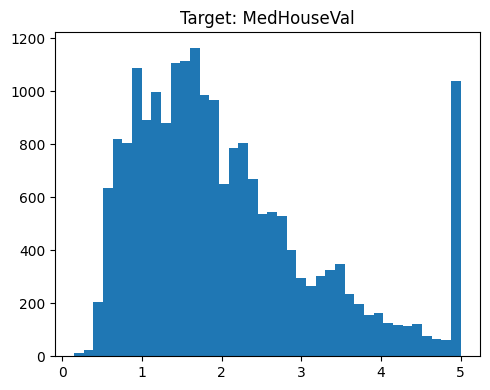

In [5]:
#we need to scale data after looking  at the describe details
#In regression prob we have linear regr, random forest regr and nn. Scaling is required mainly in linear and nn (wold=wnew+lr*df)

#lets first plot all features histogram
fig , axes= plt.subplots(2,4, figsize=(16,7))
for ax, col in zip(axes.flatten(), features_cols):
    df[col].hist(ax=ax, bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()

#lets plot target house value also
fig, ax= plt.subplots(figsize=(5,4))
ax.hist(df[target_col], bins=40)
ax.set_title(f"Target: {target_col}")
plt.tight_layout()
plt.show()



In [6]:
#lets check correlation of target variable to other features

#corr= df.corr(numeric_only=True)[target_col].drop(target_col).sort_values(key=abs, ascending=False)
corr = df.corr(numeric_only=True)[target_col].drop(target_col).sort_values(key=abs, ascending=False)
print("Correlation of each feature with the target:\n", corr)
# MedInc (median income) should be the strongest single correlate.
# Correlation only sees straight-line relationships -- it says nothing about how features
# interact, so we keep ALL 8 features even though only one correlates strongest alone

Correlation of each feature with the target:
 MedInc        0.688075
AveRooms      0.151948
Latitude     -0.144160
HouseAge      0.105623
AveBedrms    -0.046701
Longitude    -0.045967
Population   -0.024650
AveOccup     -0.023737
Name: MedHouseVal, dtype: float64


In [7]:
#lets split trian,test and val data
x=df[features_cols]
y=df[target_col]
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.2, random_state=SEED)
print(f"train shape: ", x_train.shape, y_train.shape)
print(f"test shape: ", x_test.shape, y_test.shape)

scaler= StandardScaler()
x_train_scaled= scaler.fit_transform(x_train)
x_test_scaled= scaler.transform(x_test)

train shape:  (16512, 8) (16512,)
test shape:  (4128, 8) (4128,)


In [8]:
#Try first linear regression

linear_model= LinearRegression()
linear_model.fit(x_train_scaled, y_train)
y_train_pred= linear_model.predict(x_train_scaled)
y_pred= linear_model.predict(x_test_scaled)

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
mse= mean_squared_error(y_test, y_pred)
mae= mean_absolute_error(y_test, y_pred)
r2=r2_score(y_test, y_pred)
print(f"MSE: {mse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R2: {r2:.2f}")
#display all coefficients
for(col, coef) in zip(features_cols, linear_model.coef_):
    print(f"{col}: {coef:.2f}")

MSE: 0.56
MAE: 0.53
R2: 0.58
MedInc: 0.85
HouseAge: 0.12
AveRooms: -0.29
AveBedrms: 0.34
Population: -0.00
AveOccup: -0.04
Latitude: -0.90
Longitude: -0.87


In [9]:
#Lets try with random forest. We deliberately pass unscaled data here
rf_model= RandomForestRegressor(n_estimators=200,
                                max_depth=None,
                                n_jobs=-1,
                                min_samples_leaf=5,
                                random_state=SEED)
rf_model.fit(x_train, y_train)
y_train_pred= rf_model.predict(x_train)
y_pred= rf_model.predict(x_test)

mse= mean_squared_error(y_test, y_pred)
mae= mean_absolute_error(y_test, y_pred)
r2=r2_score(y_test, y_pred)
print(f"MSE: {mse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R2: {r2:.2f}")

#get the feature importances
importances = sorted(zip(features_cols, rf_model.feature_importances_), key=lambda t: -t[1])
print("Random Forest feature importances:")
for name, imp in importances:
    print(f"{name:12s}: {imp:.4f}")

MSE: 0.26
MAE: 0.33
R2: 0.80
Random Forest feature importances:
MedInc      : 0.5651
AveOccup    : 0.1384
Latitude    : 0.0861
Longitude   : 0.0854
HouseAge    : 0.0505
AveRooms    : 0.0355
Population  : 0.0196
AveBedrms   : 0.0193
